# Capstone Project for Strategic AI Deployment


In this walkthrough, students will develop an AI-driven solution strategy tailored to a specific business problem — from business framing, through a working model, to a documented rollout plan.

**Scenario:**
Your healthcare client is struggling to predict patient readmissions. Develop an AI solution to address this issue, and prepare a proposal highlighting the business value.

**Objective:**
- Define the business problem, stakeholders, and success metrics.
- Select an AI architecture and justify the choice in an **Architecture Decision Record (ADR)**.
- Use Hospital Readmission data to build and evaluate a working model that predicts readmission risk.
- Translate model performance into a **business justification** (cost of readmission, expected savings, ROI).
- Draft a phased **implementation roadmap**, including a deployment plan and risk mitigation strategies.
- Create a 5-minute pitch to deliver for a client or internal stakeholders (optional).

**Estimated Time:** 150 minutes


### Part 1: Business Problem Framing

**Task:**
- Identify the business stakeholders for this solution (who is asking for it, and who is affected by it).
- State the business problem in one or two sentences — not "predict readmission," but *why* predicting it matters (cost, care quality, capacity).
- Define at least one measurable success metric this solution should move (e.g. reduction in 30-day readmission rate, cost avoided per prevented readmission).

Write your framing in the cell below.

**Stakeholders:**

Care management leadership (Owns the readmission-reduction goal, sponsors the project).

Discharge planners and case managers (They decide who's getting followeld-up via risk flag).

Hospital finance (Pays for avoidable readmissions and any related penalties.

Patients and their families (The one's who are being helped)



**Business Problem:**
Unplanned 30-day readmissions are expensive and often preventable with better discharge planning and follow-up. Today they got a critic scenario (The hospital only learns a patient was high-risk *after* they come back). In a future they need to flag high-risk patients *before* discharge, so the med team can focus its capacity where it matters most. 

**Success Metrics:**
- **Primary:** reduce the 30-day readmission rate among flagged patients versus the historical baseline.
- **Secondary:** cost avoided per prevented readmission, net of the cost of follow-up interventions.
- **Model metric:** recall on readmitted patients, because missing an at-risk patient is the most expensive error.


### Part 2: Load the 'hospital_readmissions_data.csv' dataset from the data directory into a Pandas DataFrame.

**Task 2:**
- Load and Preprocess the dataset.
- Perform EDA to understand patterns in the dataset
- Data Preprocessing
- Split the dataset into training and testing datasets

In [2]:
# Load and Preprocess the dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

df = pd.read_csv("data/hospital_readmissions_data.csv")
print(df.shape)
print(df['Readmitted'].value_counts())
print(df.isnull().sum())
df.describe()

(1000, 13)
No     503
Yes    497
Name: Readmitted, dtype: int64
Patient_ID                 0
Age                        0
Gender                     0
Admission_Type             0
Diagnosis                  0
Num_Lab_Procedures         0
Num_Medications            0
Num_Outpatient_Visits      0
Num_Inpatient_Visits       0
Num_Emergency_Visits       0
Num_Diagnoses              0
A1C_Result               434
Readmitted                 0
dtype: int64


,Patient_ID,Age,Num_Lab_Procedures,Num_Medications,Num_Outpatient_Visits,Num_Inpatient_Visits,Num_Emergency_Visits,Num_Diagnoses
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,500.500000,51.665000,50.836000,15.661000,2.016000,2.019000,1.956000,5.011000
std,288.819436,21.989459,28.075137,8.230177,1.399894,1.416561,1.409983,2.664203
min,1.000000,18.000000,1.000000,1.000000,0.000000,0.000000,0.000000,1.000000
25%,250.750000,34.000000,27.000000,9.000000,1.000000,1.000000,1.000000,3.000000
50%,500.500000,50.500000,52.000000,16.000000,2.000000,2.000000,2.000000,5.000000
75%,750.250000,69.000000,75.000000,23.000000,3.000000,3.000000,3.000000,7.000000
max,1000.000000,150.000000,99.000000,35.000000,4.000000,4.000000,4.000000,9.000000


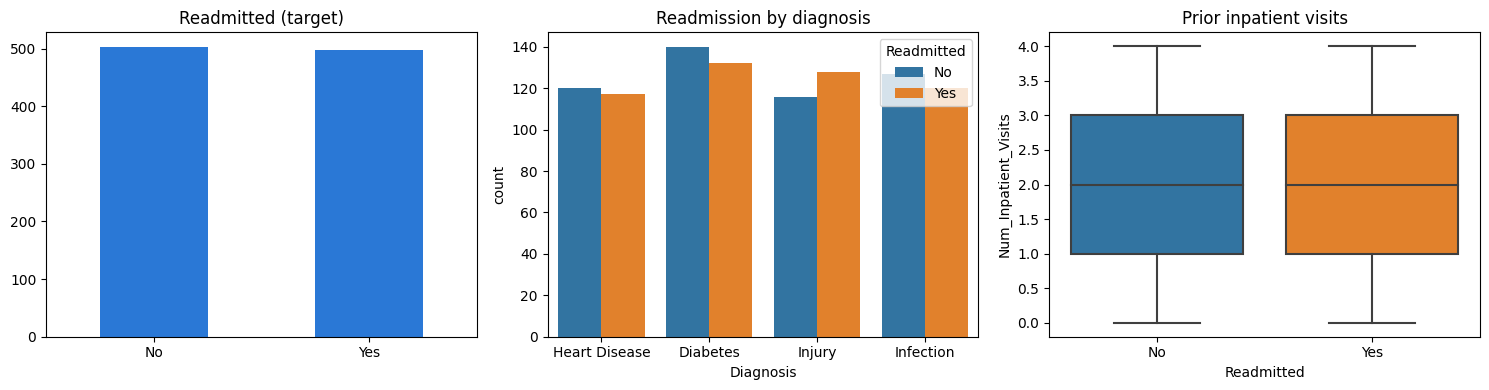

In [5]:
# Perform EDA to understand patterns in the dataset
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
df['Readmitted'].value_counts().plot(kind='bar', ax=axes[0], color='#2a78d6', rot=0, title='Readmitted (target)')
sns.countplot(data=df, x='Diagnosis', hue='Readmitted', hue_order=['No', 'Yes'], ax=axes[1])
axes[1].set_title('Readmission by diagnosis')
sns.boxplot(data=df, x='Readmitted', y='Num_Inpatient_Visits', order=['No', 'Yes'], ax=axes[2])
axes[2].set_title('Prior inpatient visits')
plt.tight_layout()
plt.show()

In [6]:
# Data Preprocessing: cleaning
df_clean = df.drop(columns=['Patient_ID'])                            
df_clean = df_clean[df_clean['Age'] <= 100]                           
df_clean['A1C_Result'] = df_clean['A1C_Result'].fillna('Not tested')  

print(df_clean.shape)
print(df_clean['A1C_Result'].value_counts())

(990, 12)
Not tested    433
Abnormal      296
Normal        261
Name: A1C_Result, dtype: int64


In [7]:
# Data Preprocessing: encoding and train/test split
X = pd.get_dummies(df_clean.drop(columns='Readmitted'), drop_first=True).astype(float)
y = (df_clean['Readmitted'] == 'Yes').astype(int)   # Yes = 1, No = 0

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(X_train.shape, X_test.shape)

(792, 16) (198, 16)


### Part 3: Build Models to train the dataset using different Machine Learning algorithms, and document your architecture choice

**Task 3:**
- Employ diverse algorithms for predicting readmission risk.
- Write an **Architecture Decision Record (ADR)** justifying the model/approach you recommend for production — not just "which model scored highest," but *why* that trade-off (interpretability, latency, maintainability, data requirements) fits this client.

In [8]:
# Train three different algorithms and compare them
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42)),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
}

results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "AUC": roc_auc_score(y_test, y_prob),
    })

results_df = pd.DataFrame(results).set_index("Model").round(3)
results_df

,Accuracy,Precision,Recall,F1,AUC
Model,,,,,
Logistic Regression,0.475,0.467,0.429,0.447,0.454
Decision Tree,0.500,0.495,0.561,0.526,0.462
Random Forest,0.419,0.402,0.357,0.378,0.462


**Architecture Decision Record (ADR) — Template**

| Field | Your Answer |
| --- | --- |
| **Title** | |
| **Status** | Proposed / Accepted |
| **Context** | What constraints (data, latency, interpretability, timeline, budget) shaped this decision? |
| **Decision** | Which architecture/algorithm are you recommending? |
| **Consequences** | What do you gain and give up with this choice? |
| **Alternatives Considered** | What else did you evaluate, and why was it not chosen? |

### Part 4: Evaluating Model & Business Justification

**Task 4:**
- Analyze model performance metrics to identify the most effective algorithm.
- Translate that performance into a business justification: estimate the cost of readmissions this model could help avoid, and weigh the trade-off between false positives (unnecessary interventions) and false negatives (missed at-risk patients).

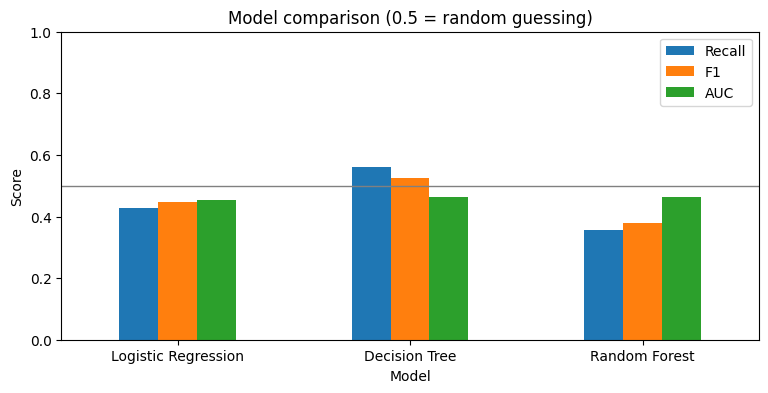

In [9]:
# Compare the models visually
results_df[["Recall", "F1", "AUC"]].plot(kind="bar", figsize=(9, 4), rot=0,
                                         title="Model comparison (0.5 = random guessing)")
plt.axhline(0.5, color="gray", linewidth=1)
plt.ylim(0, 1)
plt.ylabel("Score")
plt.show()

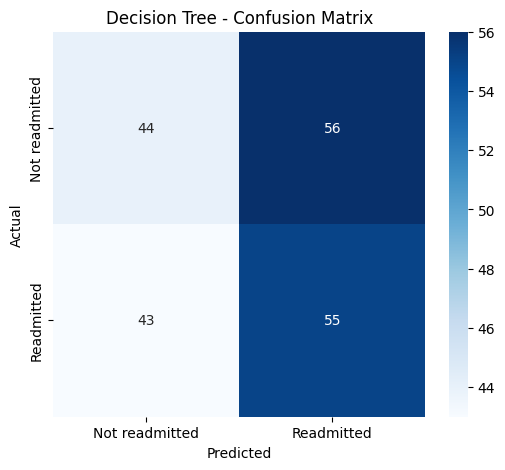

True positives (at-risk patients caught): 55
False positives (unnecessary follow-ups): 56
False negatives (at-risk patients missed): 43


In [10]:
# Confusion matrix of the recommended model (Decision Tree)
from sklearn.metrics import confusion_matrix

best_model = models["Decision Tree"]
y_pred = best_model.predict(X_test)
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Not readmitted', 'Readmitted'],
            yticklabels=['Not readmitted', 'Readmitted'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Decision Tree - Confusion Matrix')
plt.show()

print(f"True positives (at-risk patients caught): {tp}")
print(f"False positives (unnecessary follow-ups): {fp}")
print(f"False negatives (at-risk patients missed): {fn}")

**Model evaluation**
The Decision Tree is the best one, has a recall of (0.56) and F1 (0.53). 

At the other models this are the results:
- Logistic Regression (recall 0.43) 
- Random Forest (recall 0.36) are worse.


**Business justification** 

1500 per readmission

300 per follow-up

30% of readmissions prevented by follow-up

- The model flags 111 patients (55 + 56), so the follow-up cost is 33,300
- It catches 55 at-risk patients; 247,500 saved
- The 56 false positives cost only $300 each (16,800 total). 

The 43 false negatives are the ones giving an expensive error, Conclusion the model is close to random selection, so we would need to create stronger features, while right now using it as a pilot. 

### Part 5: Implementation Roadmap

**Task 5:**
- Draft a phased implementation roadmap for taking this model from prototype to production (e.g. pilot, monitoring, phased rollout).
- Identify at least two risks (data drift, clinical workflow adoption, bias/fairness, integration) and a mitigation for each.

We will first enrich the data until the model clearly beats random guessing, then test it silently alongside case managers, roll it out in one unit with humans making the final decision, and finally scale it hospital-wide with monitoring and regular retraining.

### Optional: 5-Minute Stakeholder Pitch

**Task (Optional):**
- Prepare a short pitch (5 minutes) summarizing the problem, your recommended architecture, model results, business value, and rollout plan for a client or internal stakeholder audience.